In [6]:
from specml.data import SpectroscopicData
from specml.visualization import plotting
import numpy as np
from specml.processing.masking import create_mask_from_area, apply_mask, rebuild_tissue_mask
from specml.processing.preprocessing import vector_norm, adjust_spectra_min_to_zero


test_data1 = SpectroscopicData(file_path=f'D:/Lung_Data_8cm/4F-4504-01/4F-4504-01_bot/4f-4504-01_bot.dmt')

MemoryError: Unable to allocate 32.0 GiB for an array with shape (4294968204,) and data type float64

(512, 1664, 754)
Data flattened and mask applied. Shape of processed data: (851968, 674)
(847904, 207)
Data is flattened. Reshaping it back to 3D.
Data reshaped back to 3D with shape (512, 1664, 207)
Image slice shape: (512, 1664)


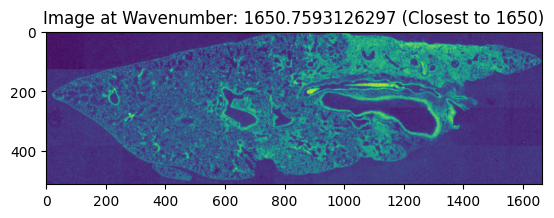

In [13]:
print(test_data1.data.shape)
test_data1.easy_preprocess(area_threshold=0.1)
print(test_data1.data.shape)
plotting.plot_image_over_wavenumber(test_data1, 1650)

In [2]:
test_data1.keep_range(950, 3550)
print(test_data1.data.shape, "1", test_data1.mask.shape)
area = test_data1.calculate_area(1600,1700)
print(test_data1.data.shape, "2", test_data1.mask.shape)
tissue_mask = create_mask_from_area(area=area)
print(test_data1.data.shape, "3", test_data1.mask.shape)
test_data1.data = apply_mask(test_data1.data, tissue_mask)
print(test_data1.data.shape, "4", test_data1.mask.shape)
test_data1.mask = rebuild_tissue_mask(test_data1, tissue_mask)
print(test_data1.data.shape, "5", test_data1.mask.shape)



(512, 1664, 674) 1 (512, 1664)
Data flattened and mask applied. Shape of processed data: (851968, 674)
(512, 1664, 674) 2 (512, 1664)
(512, 1664, 674) 3 (512, 1664)
(446706, 674) 4 (512, 1664)
(446706, 674) 5 (851968,)


In [3]:
print(test_data1.data.shape)
print(test_data1.mask.shape)

(446706, 674)
(851968,)


In [4]:
print(test_data1.data)
print()
test_data1.data = adjust_spectra_min_to_zero(test_data1.data)
print(test_data1.data)
print()
test_data1.data = vector_norm(test_data1.data)
print(test_data1.data)

[[0.02823114 0.02361901 0.02473318 ... 0.06655931 0.06752459 0.06869988]
 [0.02096636 0.01974436 0.0300463  ... 0.06600098 0.06591188 0.06653421]
 [0.0245612  0.02027241 0.02754045 ... 0.0897124  0.08909702 0.08844014]
 ...
 [0.02709416 0.03097618 0.03559011 ... 0.02700594 0.02674546 0.02542739]
 [0.03761451 0.03892342 0.04191881 ... 0.10222212 0.10188782 0.10141714]
 [0.01882762 0.02825634 0.04116455 ... 0.04274388 0.04230887 0.04080399]]

[[0.04461779 0.04000566 0.04111984 ... 0.08294597 0.08391124 0.08508654]
 [0.03897457 0.03775257 0.04805451 ... 0.08400919 0.08392009 0.08454242]
 [0.02366316 0.01937437 0.02664242 ... 0.08881436 0.08819897 0.08754209]
 ...
 [0.07650518 0.0803872  0.08500113 ... 0.07641696 0.07615648 0.07483841]
 [0.05277647 0.05408537 0.05708077 ... 0.11738408 0.11704978 0.11657909]
 [0.07017112 0.07959984 0.09250805 ... 0.09408738 0.09365238 0.09214748]]

[[0.00959316 0.00860151 0.00884107 ... 0.017834   0.01804154 0.01829424]
 [0.00826601 0.00800684 0.01019175 ..